In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [2]:
df = pd.read_csv("customer_segmentation_marketing.csv")

In [3]:
df = df.drop('id',axis=1)

In [4]:
df.describe()

,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,43.783000,88500.800000,50.685000,5.46900,26.596000,492.348670
std,15.042213,34230.771122,28.955175,2.85573,14.243654,295.744253
min,18.000000,30004.000000,1.000000,1.00000,1.000000,10.400000
25%,30.000000,57911.750000,26.000000,3.00000,15.000000,218.762500
50%,45.000000,87845.500000,50.000000,5.00000,27.000000,491.595000
75%,57.000000,116110.250000,76.000000,8.00000,39.000000,747.170000
max,69.000000,149973.000000,100.000000,10.00000,50.000000,999.740000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1000 non-null   int64  
 1   gender                1000 non-null   str    
 2   income                1000 non-null   int64  
 3   spending_score        1000 non-null   int64  
 4   membership_years      1000 non-null   int64  
 5   purchase_frequency    1000 non-null   int64  
 6   preferred_category    1000 non-null   str    
 7   last_purchase_amount  1000 non-null   float64
dtypes: float64(1), int64(5), str(2)
memory usage: 62.6 KB


In [6]:
categorical = df.select_dtypes(include=["str"]).columns.tolist()
numerical = df.select_dtypes(include=np.number).columns.tolist()

discrete = [c for c in numerical if df[c].nunique() < 10]
continuous = [c for c in numerical if df[c].nunique() >= 10]

print("Categorical Features:", categorical)
print("Numerical Features:", numerical)
print("Discrete Numerical Features:", discrete)
print("Continuous Numerical Features:", continuous)


Categorical Features: ['gender', 'preferred_category']
Numerical Features: ['age', 'income', 'spending_score', 'membership_years', 'purchase_frequency', 'last_purchase_amount']
Discrete Numerical Features: []
Continuous Numerical Features: ['age', 'income', 'spending_score', 'membership_years', 'purchase_frequency', 'last_purchase_amount']


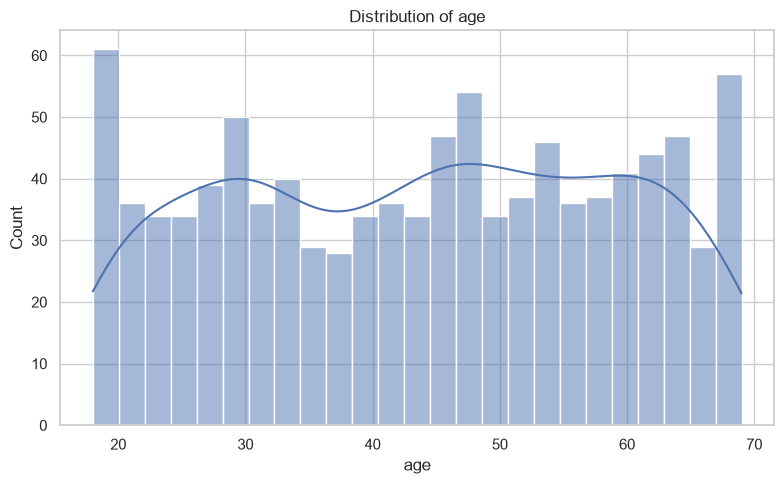

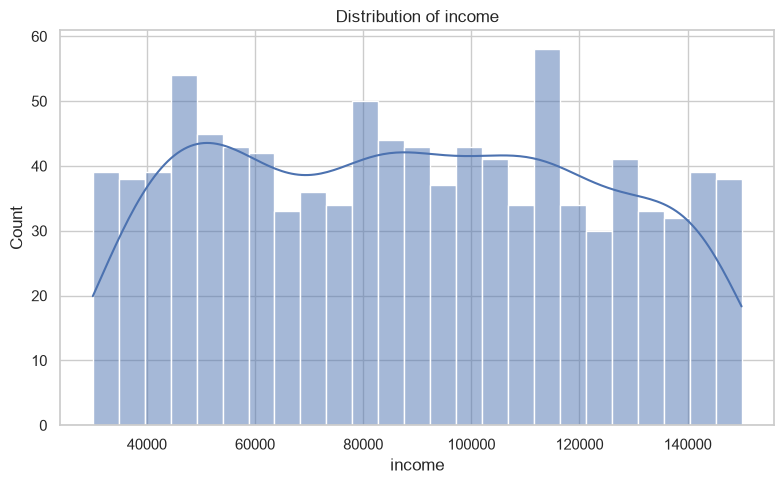

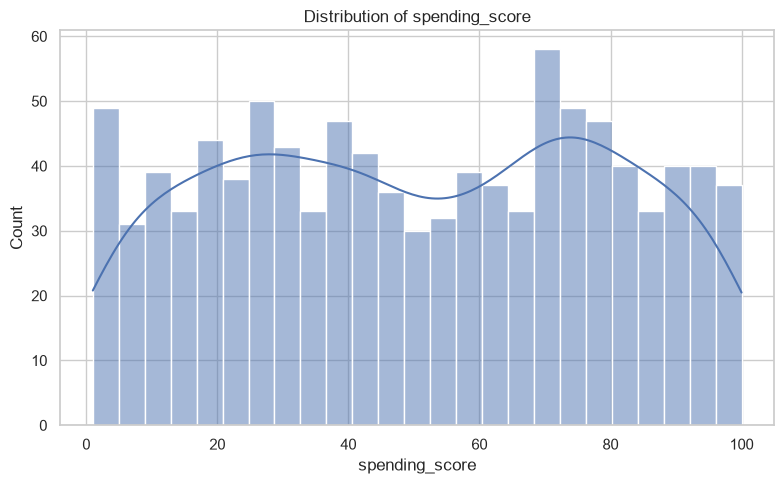

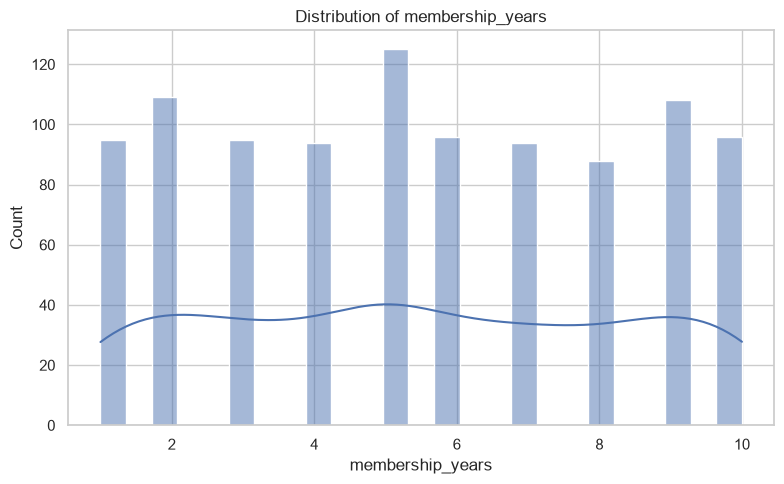

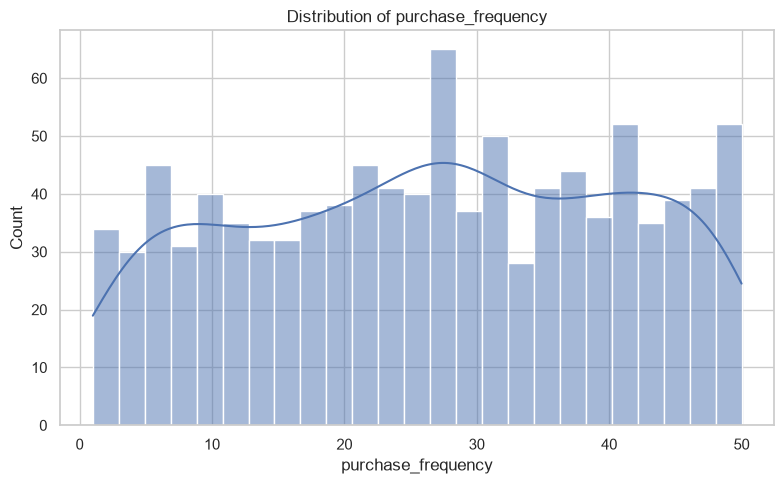

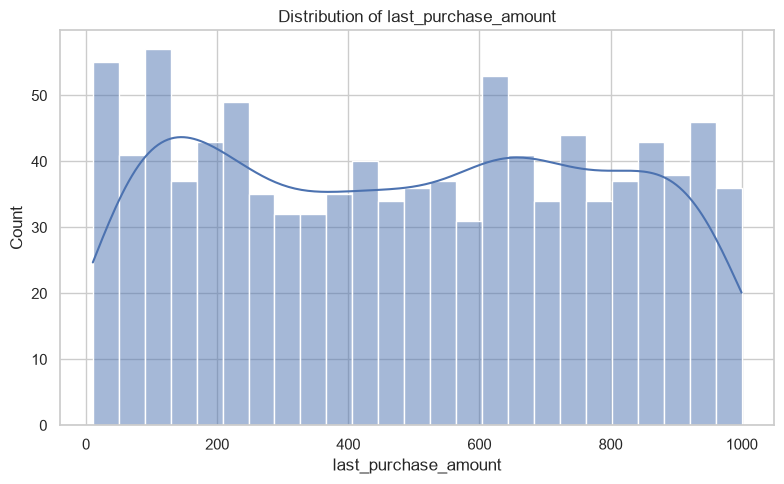

In [7]:
for col in numerical:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True, bins=25)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()


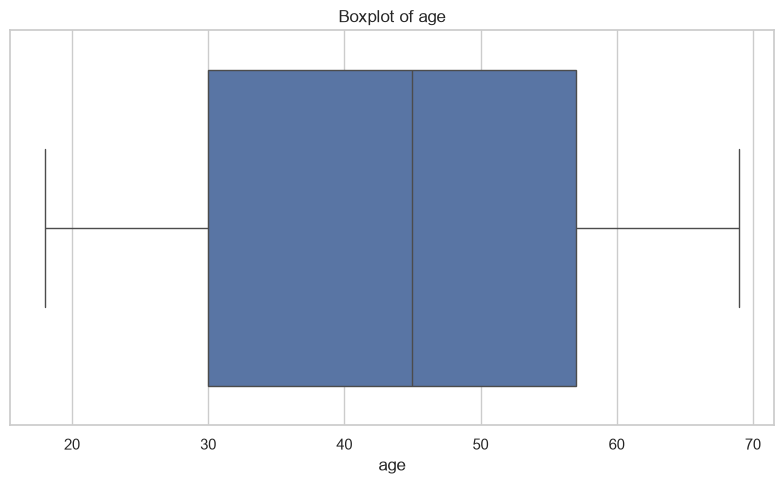

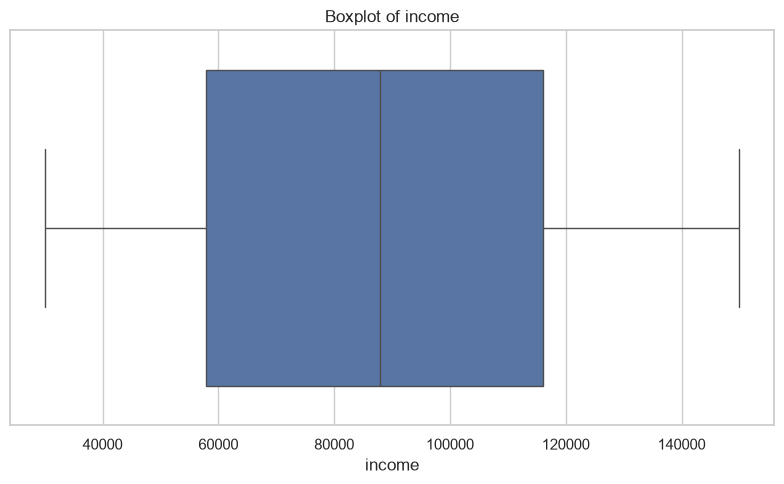

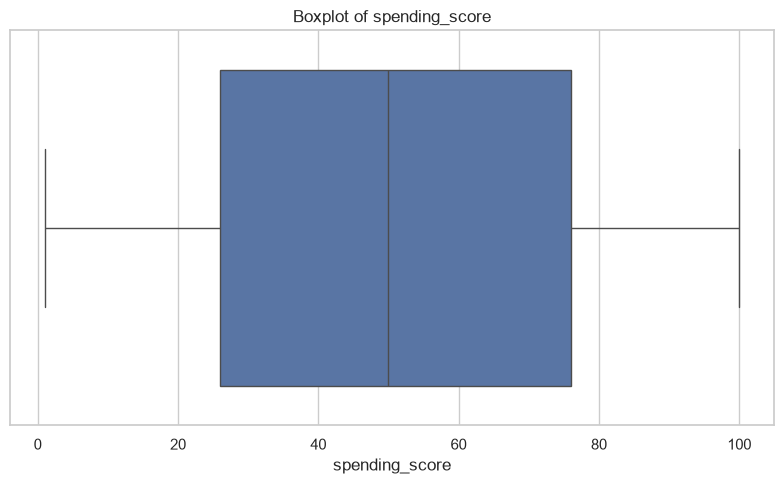

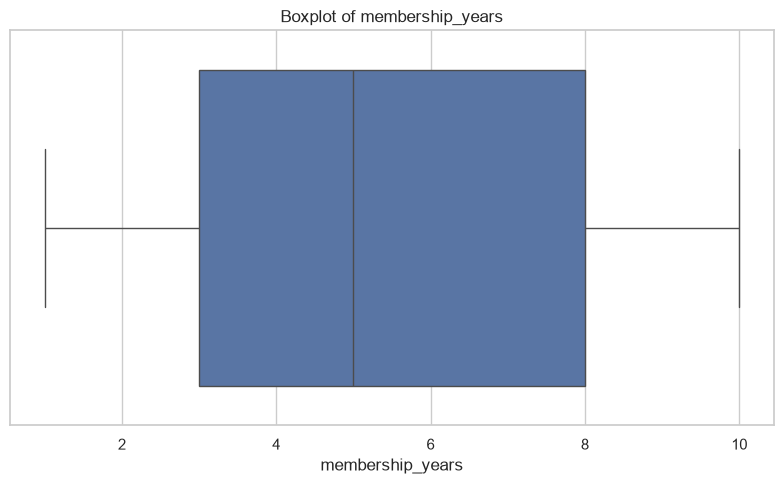

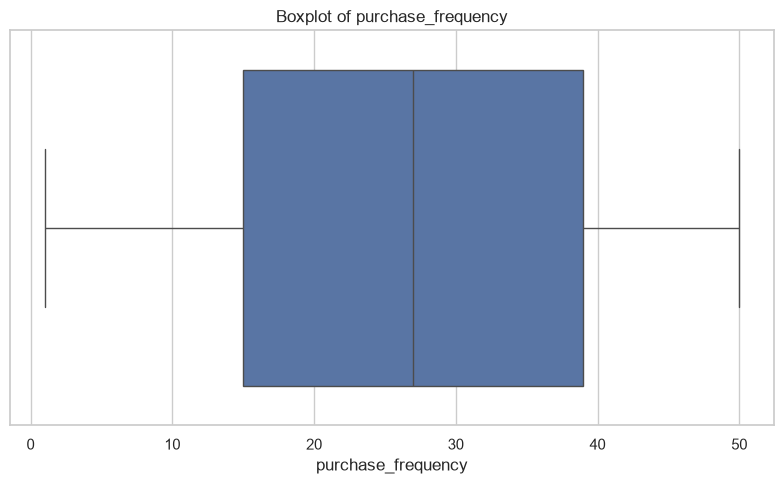

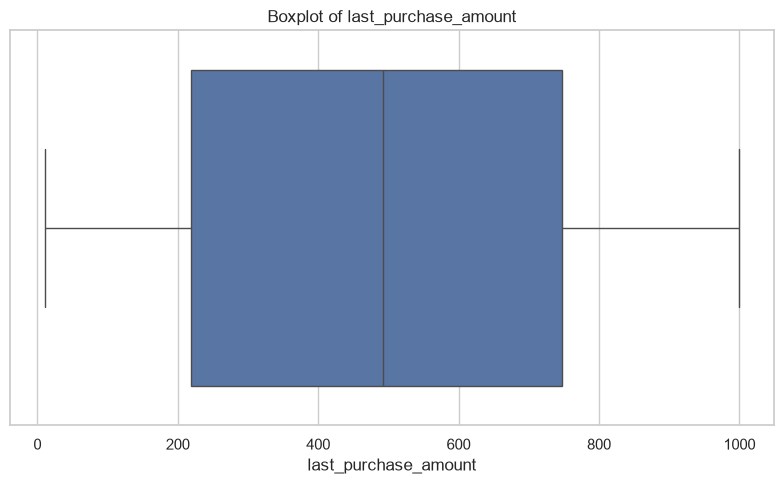

In [8]:
for col in numerical:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()


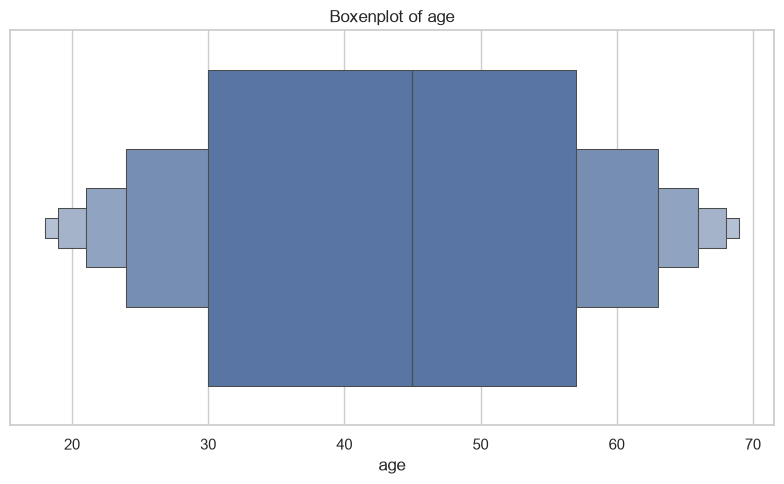

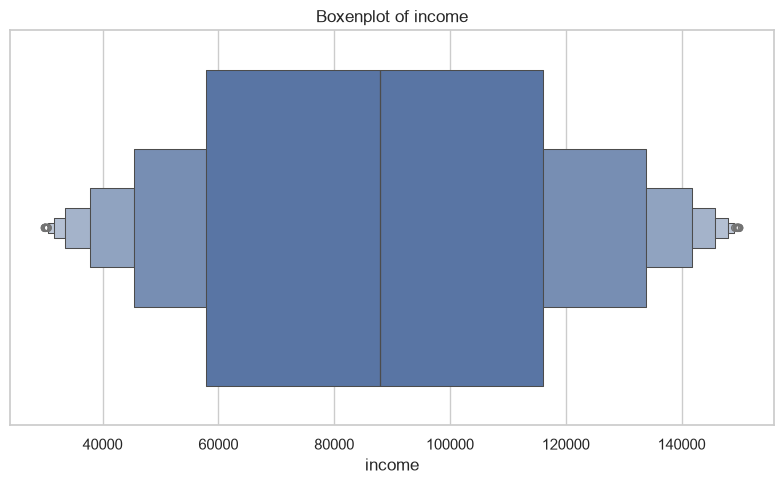

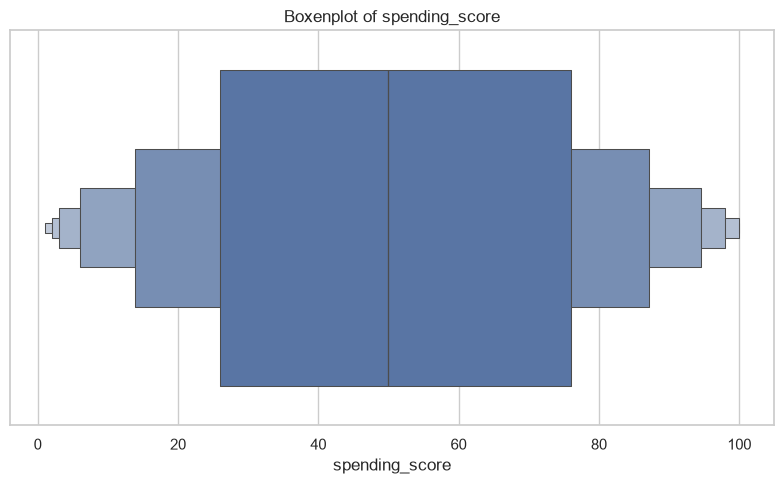

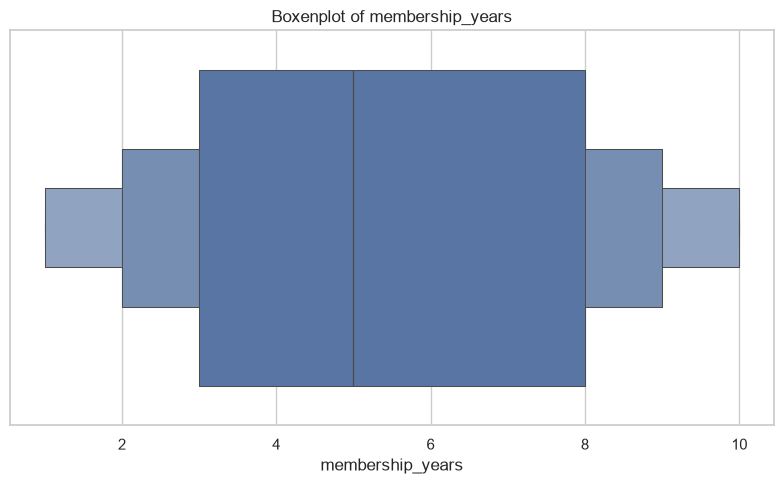

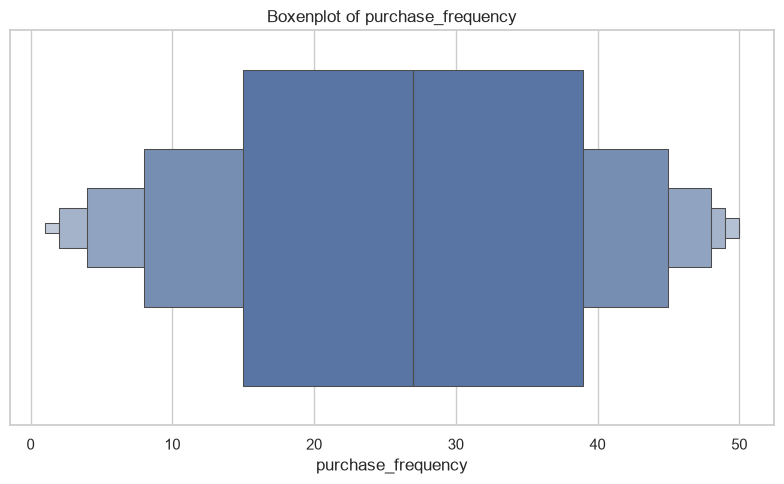

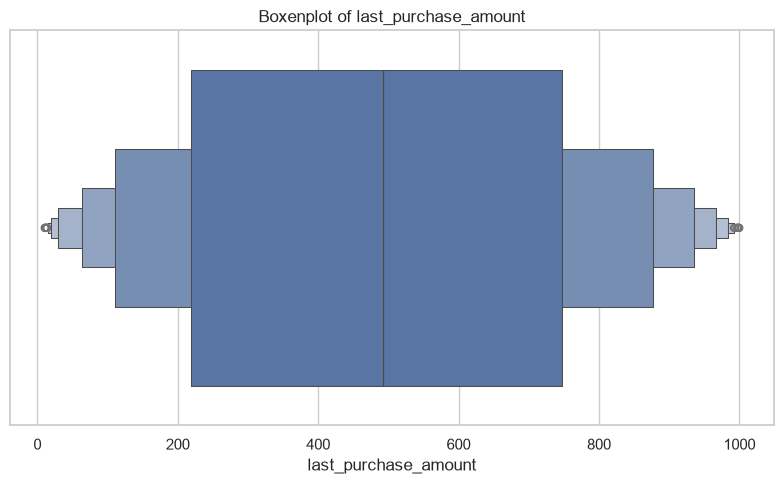

In [9]:
for col in numerical:
    plt.figure(figsize=(8, 5))
    sns.boxenplot(x=df[col])
    plt.title(f"Boxenplot of {col}")
    plt.tight_layout()
    plt.show()


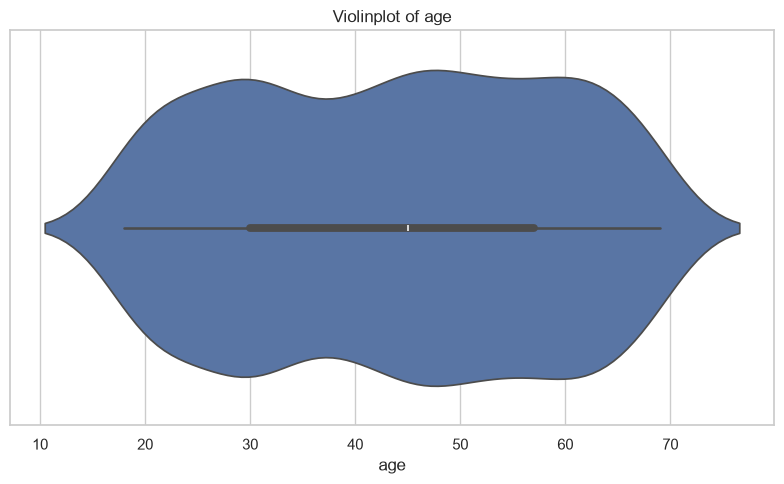

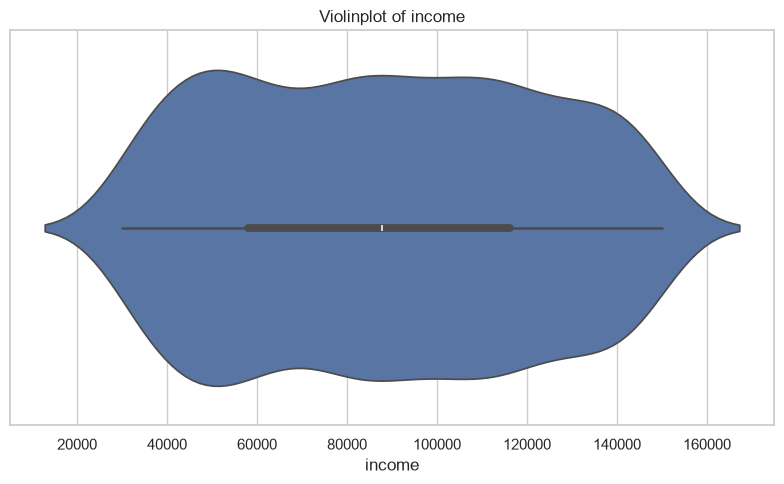

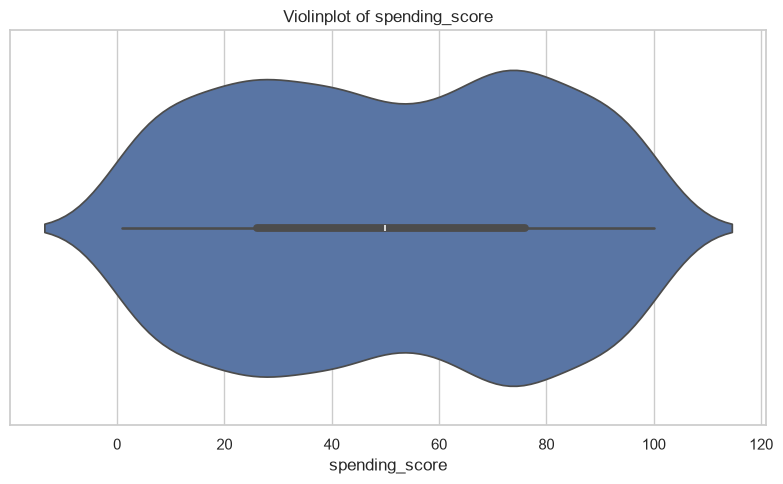

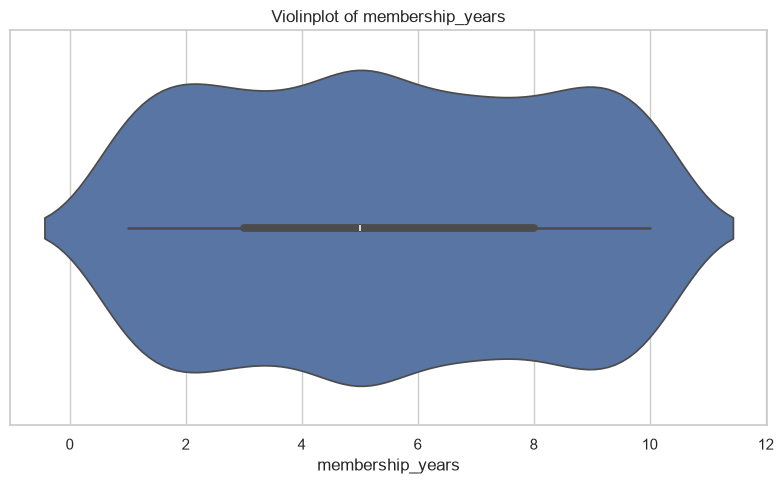

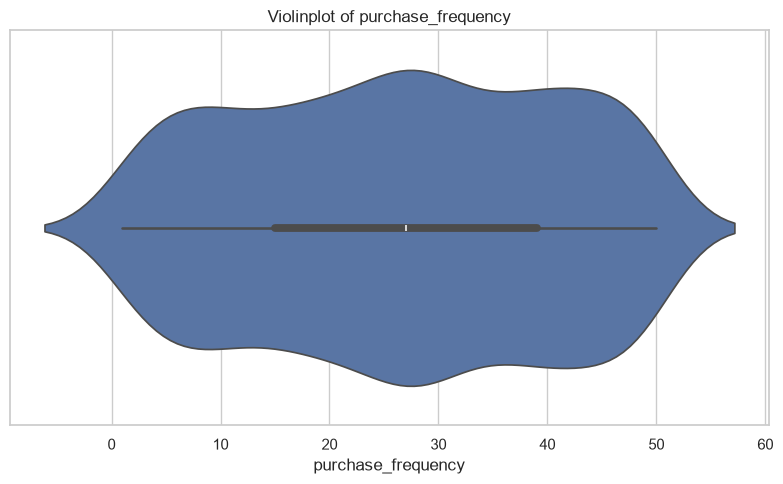

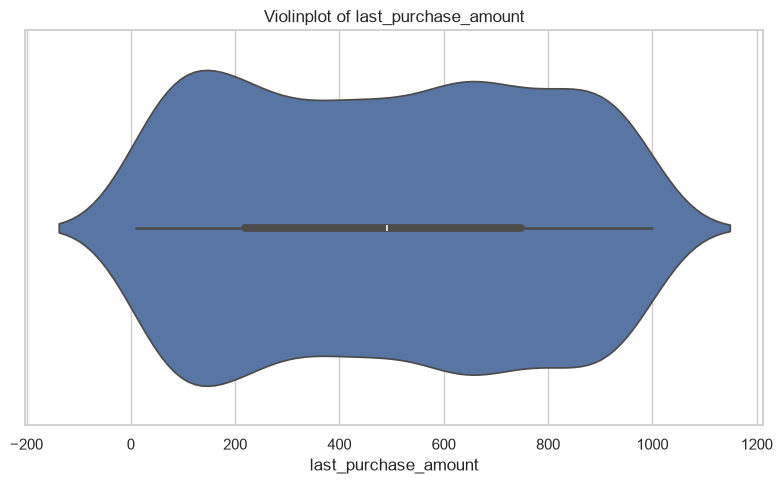

In [10]:
for col in numerical:
    plt.figure(figsize=(8, 5))
    sns.violinplot(x=df[col])
    plt.title(f"Violinplot of {col}")
    plt.tight_layout()
    plt.show()


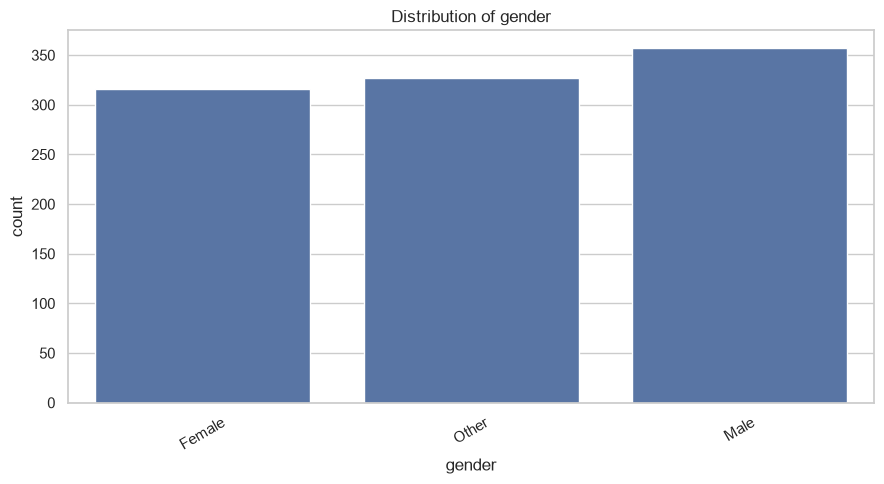

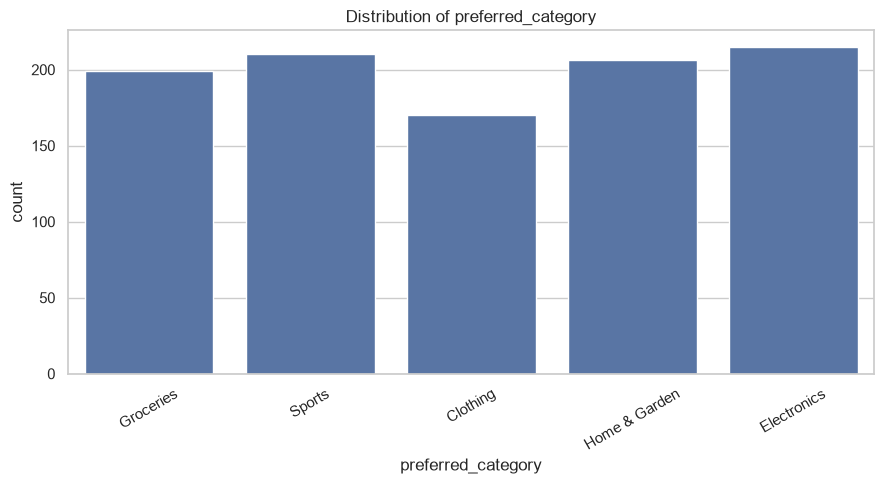

In [11]:
for col in categorical:
    if df[col].nunique() <= 15:
        plt.figure(figsize=(9, 5))
        sns.countplot(data=df, x=col)
        plt.title(f"Distribution of {col}")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


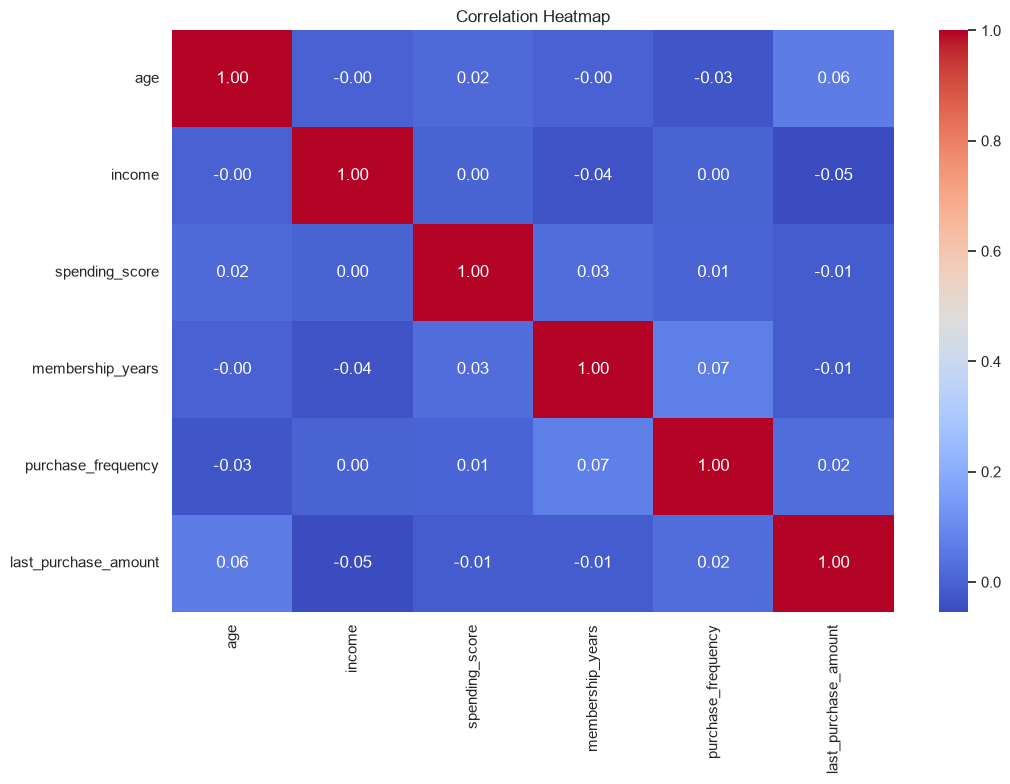

In [12]:
if len(continuous) > 1:
    plt.figure(figsize=(11, 8))
    sns.heatmap(df[continuous].corr(), annot=True, fmt=".2f", cmap="coolwarm")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


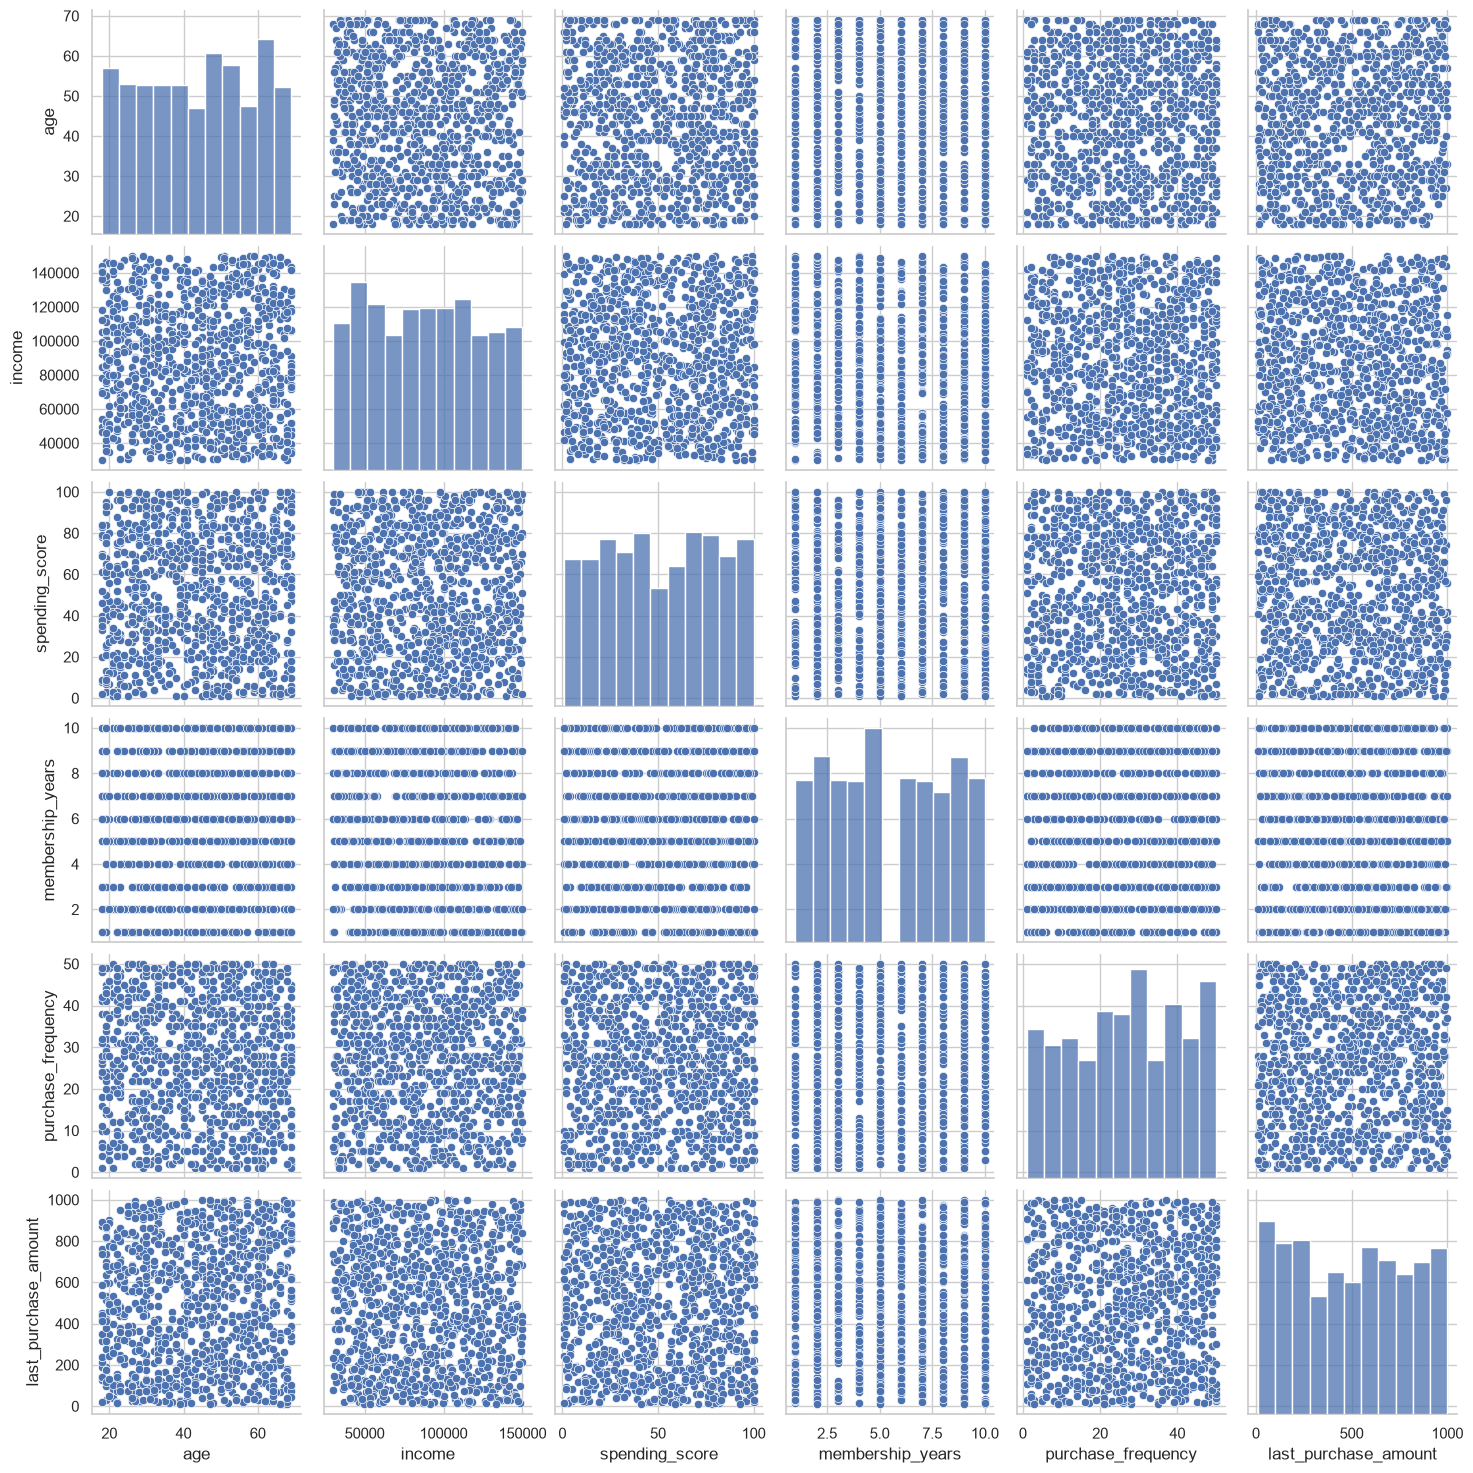

In [13]:
if len(numerical) >= 2:
    sns.pairplot(df[numerical])
    plt.show()


In [14]:
X_numeric = df[numerical].copy()
X_numeric = X_numeric.fillna(X_numeric.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

if len(categorical) > 0:
    try:
        ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
    except TypeError:
        ohe = OneHotEncoder(drop="first", sparse=False, handle_unknown="ignore")
    X_categorical = ohe.fit_transform(df[categorical].fillna("Missing"))
    X_final = np.hstack((X_scaled, X_categorical))
else:
    X_final = X_scaled

print("Final Feature Matrix Shape:", X_final.shape)


Final Feature Matrix Shape: (1000, 12)


In [15]:
k_values = range(2, 11)
k_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_final)
    k_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_final, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_final, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_final, labels)
    })

k_metrics = pd.DataFrame(k_results)
display(k_metrics)


,K,Inertia,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,6316.565382,0.107435,124.931440,2.786201
1,3,5823.188981,0.098981,109.924202,2.450604
2,4,5429.999381,0.101057,102.550753,2.331896
3,5,5118.178924,0.103557,96.671868,2.067692
4,6,4857.527092,0.104659,92.072961,1.926493
5,7,4626.209998,0.107568,88.758136,1.882044
6,8,4462.091523,0.105458,84.009519,1.898434
7,9,4314.107845,0.107858,80.202381,1.862649
8,10,4187.303174,0.106915,76.706949,1.798753


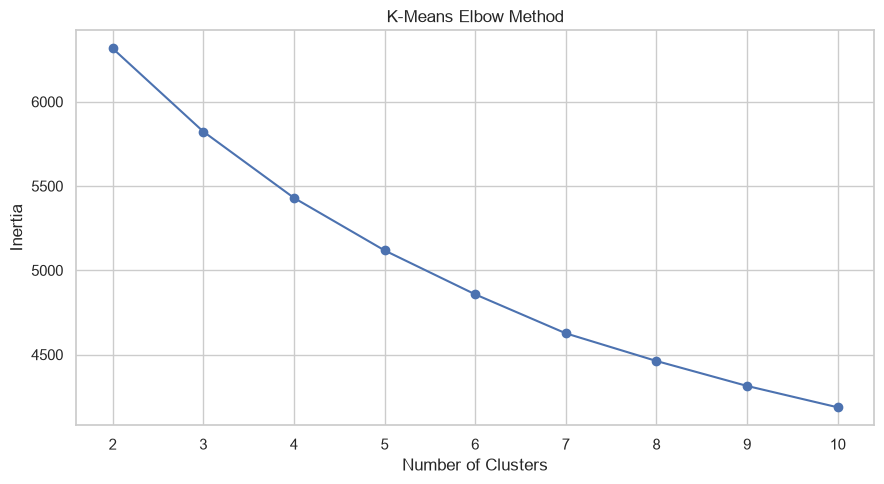

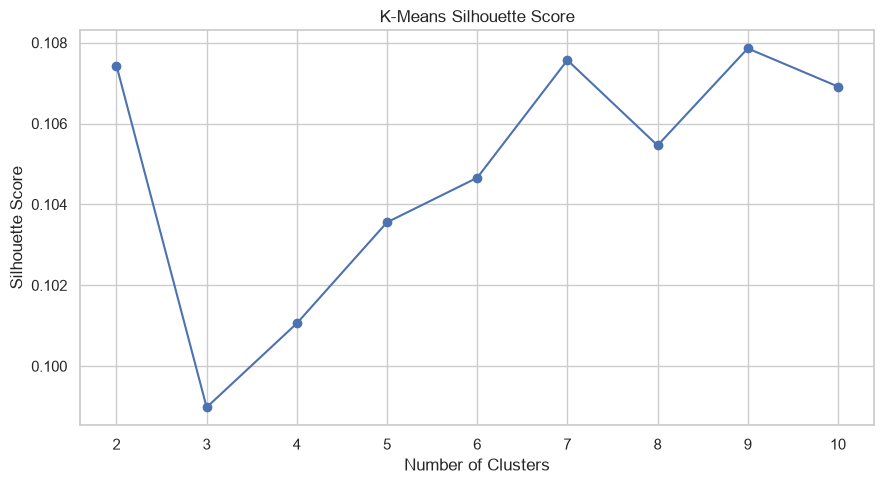

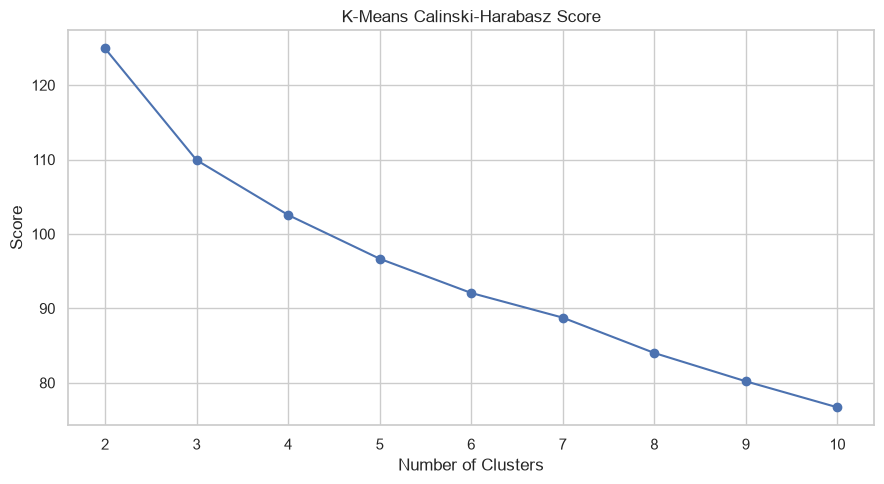

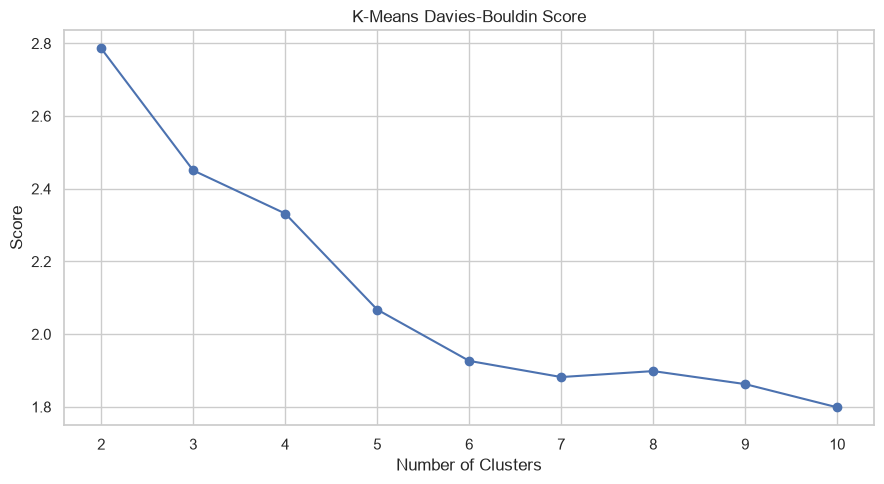

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(k_metrics["K"], k_metrics["Inertia"], marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(k_metrics["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(k_metrics["K"], k_metrics["Silhouette Score"], marker="o")
plt.title("K-Means Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(k_metrics["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(k_metrics["K"], k_metrics["Calinski-Harabasz Score"], marker="o")
plt.title("K-Means Calinski-Harabasz Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")
plt.xticks(k_metrics["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(k_metrics["K"], k_metrics["Davies-Bouldin Score"], marker="o")
plt.title("K-Means Davies-Bouldin Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")
plt.xticks(k_metrics["K"])
plt.tight_layout()
plt.show()


In [17]:
X_numeric = df[numerical].copy()
X_numeric = X_numeric.fillna(X_numeric.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

if len(categorical) > 0:
    try:
        ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
    except TypeError:
        ohe = OneHotEncoder(drop="first", sparse=False, handle_unknown="ignore")
    X_categorical = ohe.fit_transform(df[categorical].fillna("Missing"))
    X_final = np.hstack((X_pca_full, X_categorical))
else:
    X_final = X_scaled

print("Final Feature Matrix Shape:", X_final.shape)


Final Feature Matrix Shape: (1000, 12)


In [18]:
k_values = range(2, 11)
k_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_final)
    k_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_final, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_final, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_final, labels)
    })

k_metrics = pd.DataFrame(k_results)
display(k_metrics)


,K,Inertia,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,6316.565382,0.107435,124.931440,2.786201
1,3,5823.188981,0.098981,109.924202,2.450604
2,4,5429.999381,0.101057,102.550753,2.331896
3,5,5118.178924,0.103557,96.671868,2.067692
4,6,4857.527092,0.104659,92.072961,1.926493
5,7,4626.209998,0.107568,88.758136,1.882044
6,8,4462.091523,0.105458,84.009519,1.898434
7,9,4314.107845,0.107858,80.202381,1.862649
8,10,4187.303174,0.106915,76.706949,1.798753


In [19]:
kmeans_k = int(k_metrics.loc[k_metrics["Silhouette Score"].idxmax(), "K"])
kmeans_model = KMeans(n_clusters=kmeans_k, random_state=42, n_init=20)
kmeans_labels = kmeans_model.fit_predict(X_final)

df["KMeans_Cluster"] = kmeans_labels

print("Optimal K-Means Clusters:", kmeans_k)
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("Customers"))


Optimal K-Means Clusters: 9


,Customers
KMeans_Cluster,
0,115
1,99
2,122
3,89
4,105
5,129
6,124
7,120
8,97


In [20]:
kmeans_final_metrics = pd.DataFrame([{
    "Model": "K-Means",
    "Clusters": kmeans_k,
    "Silhouette Score": silhouette_score(X_final, kmeans_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_final, kmeans_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_final, kmeans_labels)
}])

display(kmeans_final_metrics)


,Model,Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,9,0.107858,80.202381,1.862649


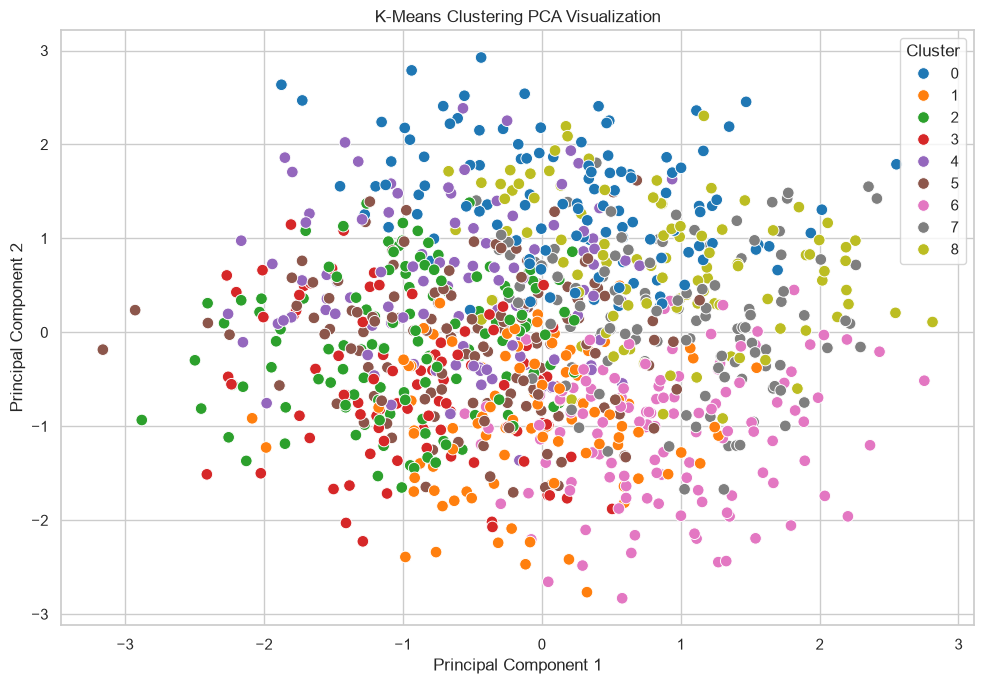

Explained Variance Ratio: [0.15345044 0.15251482]
Total Explained Variance: 0.30596525292582744


In [21]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_final)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette="tab10", s=70)
plt.title("K-Means Clustering PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", pca.explained_variance_ratio_.sum())


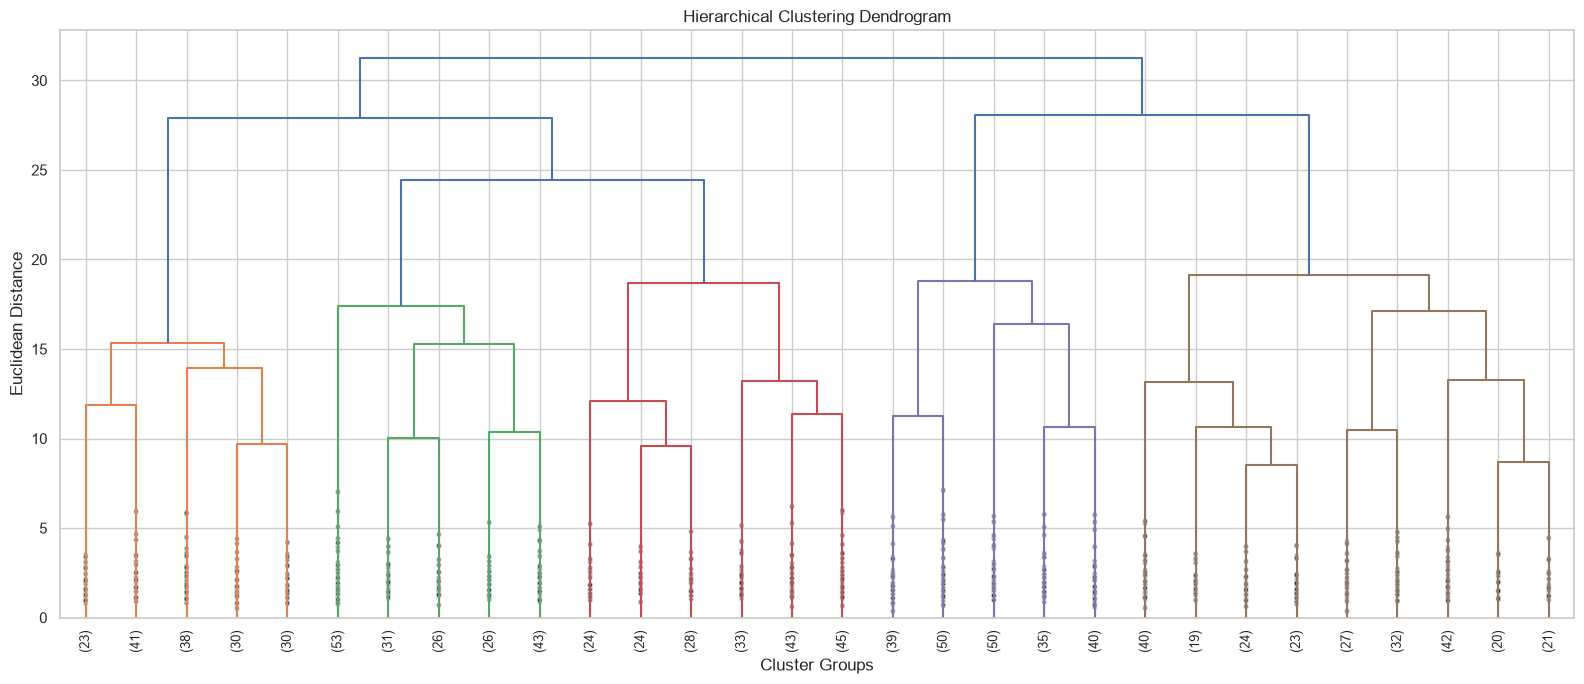

In [22]:
linkage_matrix = linkage(X_final, method="ward")

plt.figure(figsize=(16, 7))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()


In [23]:
hierarchical_results = []

for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_final)
    hierarchical_results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_final, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_final, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_final, labels)
    })

hierarchical_metrics = pd.DataFrame(hierarchical_results)
display(hierarchical_metrics)


,K,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,0.067167,73.513390,3.616664
1,3,0.052776,70.587275,2.931855
2,4,0.056308,72.262366,2.671749
3,5,0.061226,70.492709,2.498291
4,6,0.055451,65.072486,2.517021
5,7,0.048444,61.686121,2.466575
6,8,0.050525,59.628414,2.392253
7,9,0.051394,57.617786,2.334244
8,10,0.052135,56.196368,2.264687


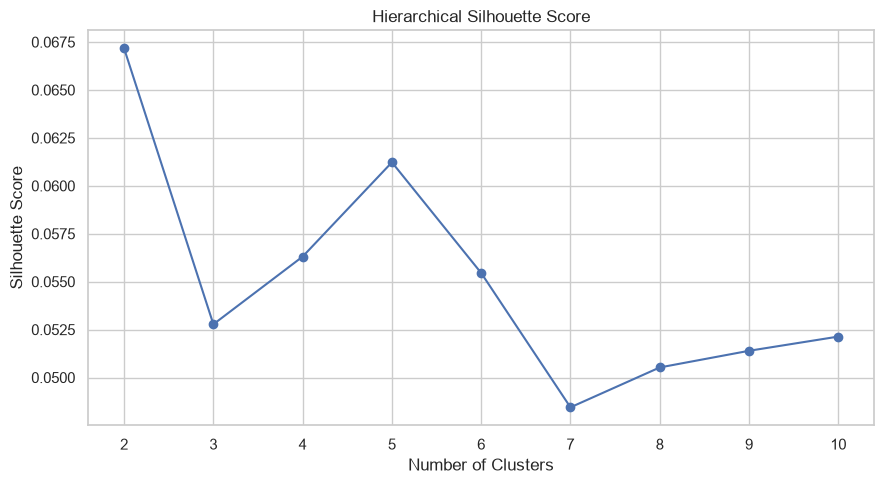

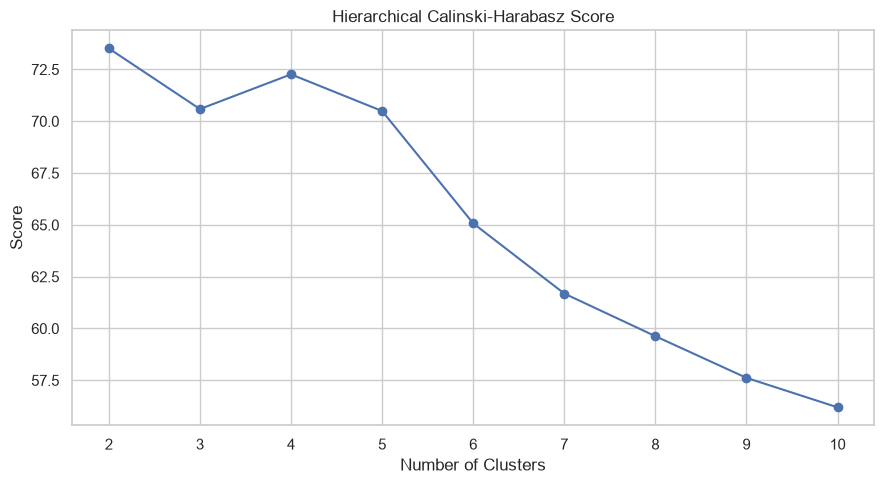

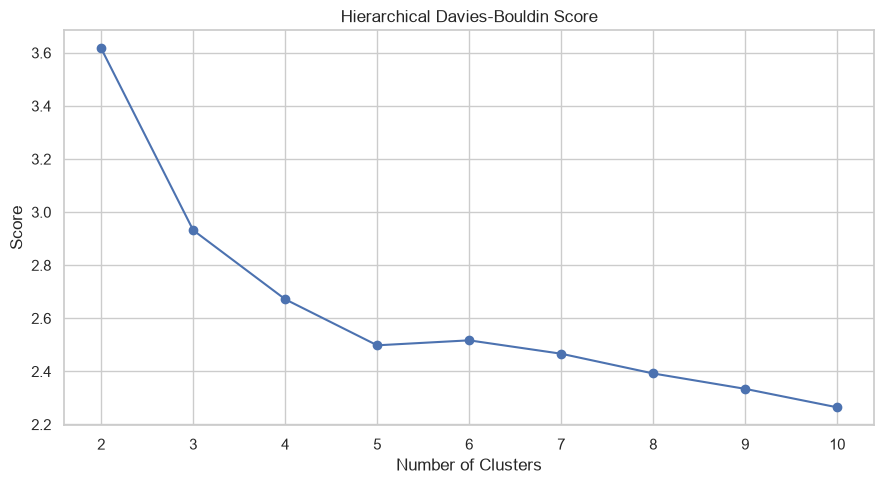

In [24]:
plt.figure(figsize=(9, 5))
plt.plot(hierarchical_metrics["K"], hierarchical_metrics["Silhouette Score"], marker="o")
plt.title("Hierarchical Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(hierarchical_metrics["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(hierarchical_metrics["K"], hierarchical_metrics["Calinski-Harabasz Score"], marker="o")
plt.title("Hierarchical Calinski-Harabasz Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")
plt.xticks(hierarchical_metrics["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(hierarchical_metrics["K"], hierarchical_metrics["Davies-Bouldin Score"], marker="o")
plt.title("Hierarchical Davies-Bouldin Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")
plt.xticks(hierarchical_metrics["K"])
plt.tight_layout()
plt.show()


In [25]:
hierarchical_k = int(
    hierarchical_metrics.loc[
        hierarchical_metrics["Silhouette Score"].idxmax(), "K"
    ]
)

hierarchical_model = AgglomerativeClustering(
    n_clusters=hierarchical_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_final)
df["Hierarchical_Cluster"] = hierarchical_labels

print("Optimal Hierarchical Clusters:", hierarchical_k)
display(df["Hierarchical_Cluster"].value_counts().sort_index().to_frame("Customers"))


Optimal Hierarchical Clusters: 2


,Customers
Hierarchical_Cluster,
0,462
1,538


In [26]:
hierarchical_final_metrics = pd.DataFrame([{
    "Model": "Hierarchical",
    "Clusters": hierarchical_k,
    "Silhouette Score": silhouette_score(X_final, hierarchical_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_final, hierarchical_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_final, hierarchical_labels)
}])

display(hierarchical_final_metrics)


,Model,Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,Hierarchical,2,0.067167,73.51339,3.616664


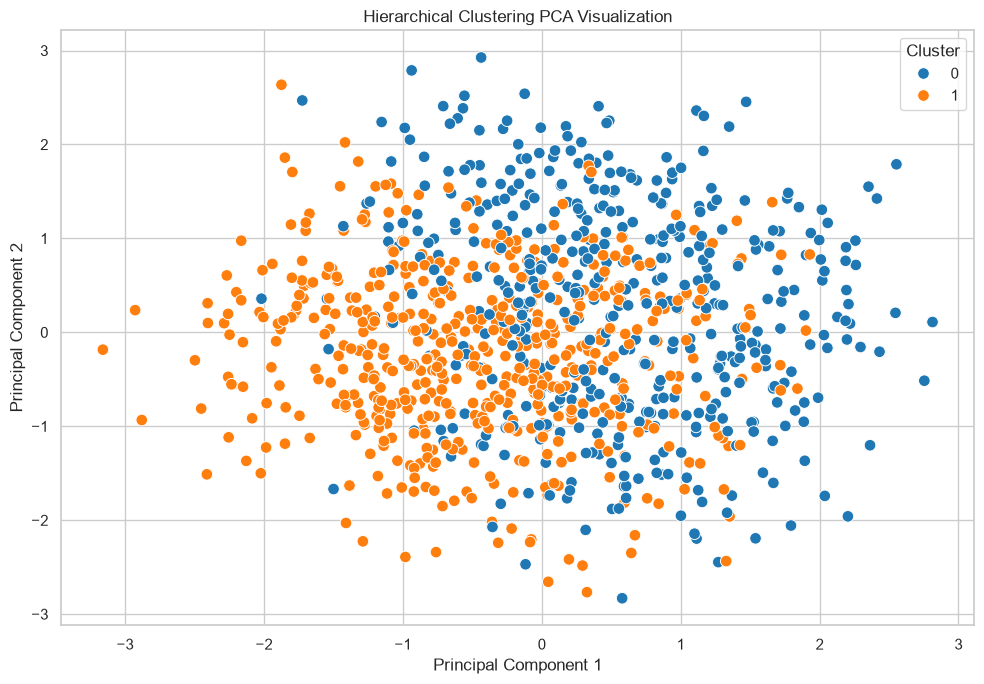

In [27]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hierarchical_labels, palette="tab10", s=70)
plt.title("Hierarchical Clustering PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


,Model,Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,9,0.107858,80.202381,1.862649
1,Hierarchical,2,0.067167,73.513390,3.616664


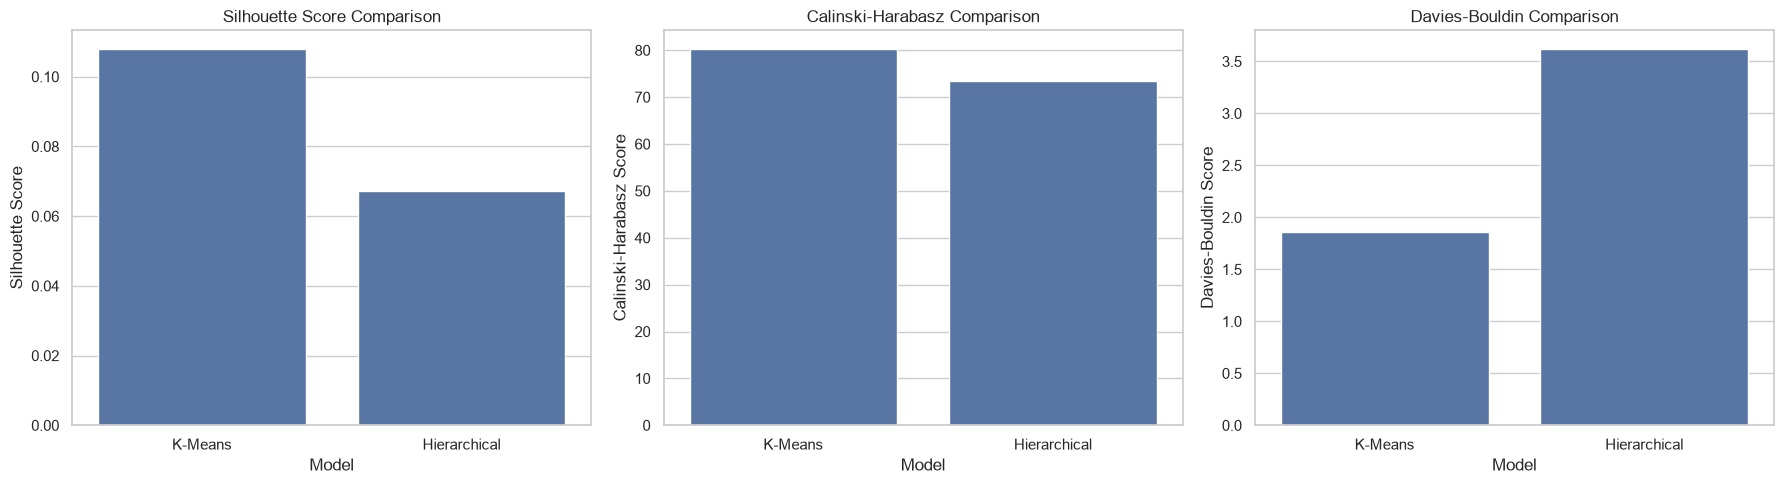

In [28]:
comparison_metrics = pd.concat(
    [kmeans_final_metrics, hierarchical_final_metrics],
    ignore_index=True
)

display(comparison_metrics)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=comparison_metrics, x="Model", y="Silhouette Score", ax=axes[0])
axes[0].set_title("Silhouette Score Comparison")

sns.barplot(data=comparison_metrics, x="Model", y="Calinski-Harabasz Score", ax=axes[1])
axes[1].set_title("Calinski-Harabasz Comparison")

sns.barplot(data=comparison_metrics, x="Model", y="Davies-Bouldin Score", ax=axes[2])
axes[2].set_title("Davies-Bouldin Comparison")

plt.tight_layout()
plt.show()


In [29]:
for model_name, cluster_col in [
    ("K-Means", "KMeans_Cluster"),
    ("Hierarchical", "Hierarchical_Cluster")
]:
    print(f"\n{model_name} Cluster Profile")
    if numerical:
        display(df.groupby(cluster_col)[numerical].mean().round(2))

    if categorical:
        for col in categorical:
            if df[col].nunique() <= 15:
                profile = pd.crosstab(
                    df[cluster_col],
                    df[col],
                    normalize="index"
                ) * 100
                print(f"{col} Distribution (%)")
                display(profile.round(2))



K-Means Cluster Profile


,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
KMeans_Cluster,,,,,,
0,55.77,56756.10,69.88,4.15,23.65,715.41
1,28.19,114676.90,30.60,4.54,38.19,514.36
2,28.30,87245.66,48.92,3.55,11.90,540.48
3,47.08,118460.54,82.79,3.81,21.75,236.42
4,56.60,105049.33,30.00,2.74,34.70,513.01
5,52.93,88864.57,34.22,7.05,14.30,228.82
6,33.44,66473.95,65.84,7.14,35.39,233.72
7,47.77,110174.79,70.28,8.34,32.49,741.14
8,44.20,56457.97,21.87,7.09,30.23,730.66


gender Distribution (%)


gender,Female,Male,Other
KMeans_Cluster,,,
0,28.70,24.35,46.96
1,25.25,49.49,25.25
2,36.89,31.15,31.97
3,30.34,40.45,29.21
4,32.38,30.48,37.14
5,32.56,33.33,34.11
6,39.52,40.32,20.16
7,29.17,30.00,40.83
8,26.80,46.39,26.80


preferred_category Distribution (%)


...

,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
Hierarchical_Cluster,,,,,,
0,42.88,65853.35,54.59,5.99,28.60,559.53
1,44.56,107948.98,47.33,5.02,24.87,434.66


gender Distribution (%)


gender,Female,Male,Other
Hierarchical_Cluster,,,
0,29.44,34.63,35.93
1,33.46,36.62,29.93


preferred_category Distribution (%)


preferred_category,Clothing,Electronics,Groceries,Home & Garden,Sports
Hierarchical_Cluster,,,,,
0,18.4,24.24,18.18,17.53,21.65
1,15.8,19.14,21.38,23.23,20.45
